# 03 - Data Curation

Curates subsets of nuScenes mini keyframes using metadata only, then measures distribution changes. No model is trained, and distribution metrics do not establish training benefit.

**Clean environment.** Use Python 3.11 or 3.12. From the repository root, install the notebook extra with `python -m pip install -e ".[notebooks]"`. Run `extract`, `curate` for each strategy, and `compare` as shown in the README first. The notebook discovers the project root and reads the generated reports without local absolute paths.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

# Locate the project root portably (works from notebooks/ locally; on Colab, clone the repo and run from it).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
OUT = ROOT / "data" / "processed" / "scenario_intelligence"
assert (OUT / "scenarios.json").exists(), "Run: python scripts/scenario_intelligence.py extract"

from scenarioforge.scenario_intelligence import reporting as rep
dataset_id, records = rep.load_scenarios(OUT / "scenarios.json")
print(dataset_id, len(records), "scenarios (keyframe-level metadata only)")

nuscenes:v1.0-mini 404 scenarios (keyframe-level metadata only)


## 1. Strategies
`random` (seeded baseline), `frequency` (highest rarity), `diversity` (greedy normalized-entropy gain), `weighted_interest` (scenario-interest ranking). Selection is deterministic for a given seed and input.

In [2]:
STRATS = ['random', 'frequency', 'diversity', 'weighted_interest']
reports = {s: rep.read_json(OUT / f'comparison_curation_{s}_n60_seed42.json') for s in STRATS}
print('subset size:', reports['random']['selected_count'], 'of', reports['random']['original_count'])

subset size: 60 of 404


## 2. Before / after distribution metrics

In [3]:
print(f"{'strategy':20s} {'H_norm orig':>11s} {'H_norm cur':>10s} {'JSD bits':>9s} {'cat cov':>8s}")
for s, r in reports.items():
    e = r['normalized_entropy']
    print(f"{s:20s} {e['original']:11.3f} {e['curated']:10.3f} {r['category_jsd_bits']:9.3f} {r['category_coverage']:8.3f}")

strategy             H_norm orig H_norm cur  JSD bits  cat cov
random                     0.594      0.591     0.002    0.944
frequency                  0.594      0.636     0.100    0.944
diversity                  0.594      0.687     0.040    0.944
weighted_interest          0.594      0.634     0.103    0.944


The reported normalized category entropy is computed from annotated-object counts pooled across the selected keyframes. Higher entropy means a more even object-category mix; it does **not** mean the curated subset preserves the original distribution. JSD measures distribution shift, and seeded random sampling is the same-budget preservation baseline. A diversity strategy may intentionally move away from the original distribution. Neither entropy nor JSD demonstrates improved model training performance; that requires controlled training and held-out evaluation.

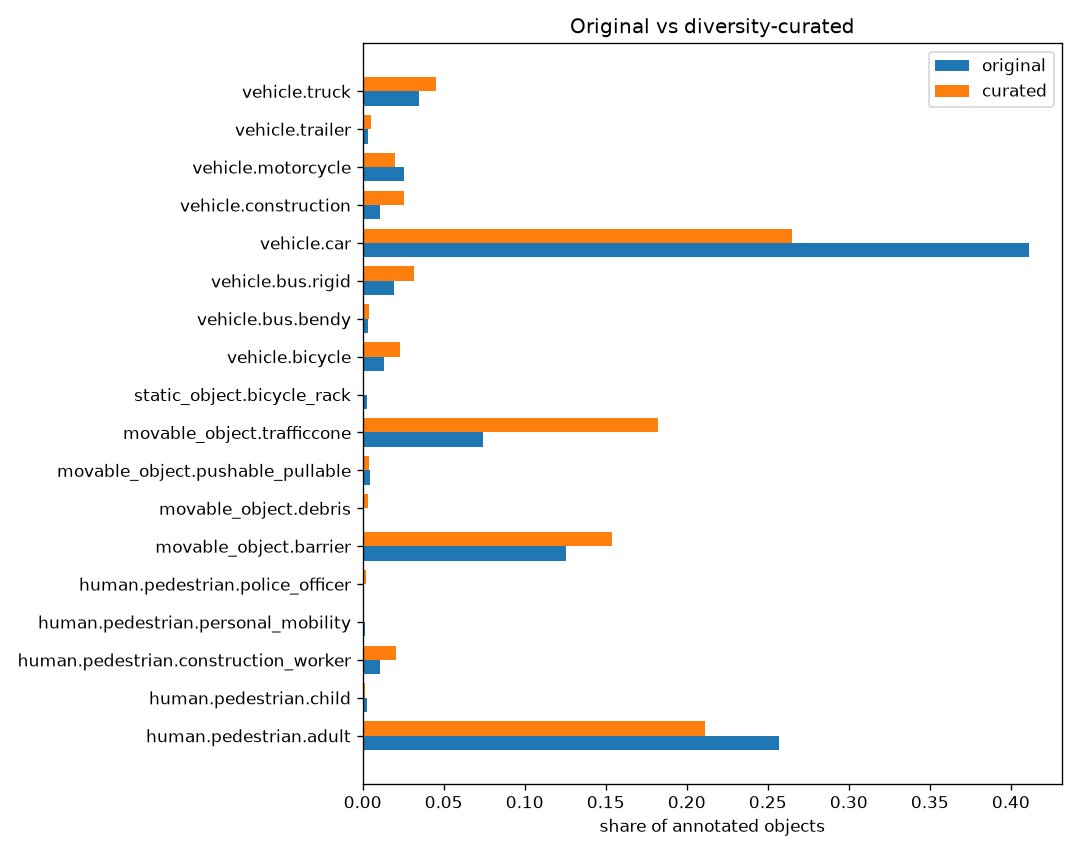

In [4]:
d = reports['diversity']['category_distribution']
rep.plot_grouped_distribution(d['original'], d['curated'], 'Original vs diversity-curated', OUT / 'plots' / 'nb_compare.png')
from IPython.display import Image; Image(OUT / 'plots' / 'nb_compare.png')

## 3. Manifest
Manifests record strategy, seed, constraints, selected ids with scores, and a SHA-256 of the contents. They contain no timestamps, so reruns are byte-identical.

In [5]:
m = rep.read_json(OUT / 'curation_diversity_n60_seed42_manifest.json')
print({k: m[k] for k in m if k not in ('selected', 'rejected_by_reason')} if False else list(m))
print('sha256:', m['manifest_sha256'])
print('first selected:', m['selected'][0])

['category_distribution_original', 'category_distribution_selected', 'config', 'counts', 'dataset_source_id', 'input_digest_sha256', 'manifest_sha256', 'manifest_version', 'rejected_by_reason', 'requested_count_satisfied', 'scope', 'selected', 'shortfall_reason']
sha256: c2426f26664370cf3e537414ac0eb3d6a1a3db0cac61c65e4070cff6b03d9c02
first selected: {'sample_id': '4246e57f018745c9b2bc68feb3d71b58', 'scene_id': 'cc8c0bf57f984915a77078b10eb33198', 'scene_name': 'scene-0061', 'selection_rank': 1, 'selection_score': None, 'timestamp': 1532402940797343}


## 4. Reproducibility check
Re-curate in-process and compare manifest hashes.

In [6]:
from scenarioforge.scenario_intelligence.curation_engine import CurationConfig, curate
from scenarioforge.scenario_intelligence.rarity_analyzer import analyze_rarity
from scenarioforge.scenario_intelligence.duplicate_detector import compute_similarity, DuplicateConfig
rar = analyze_rarity(records)
sim = compute_similarity(records, DuplicateConfig())
res = curate(records, CurationConfig(strategy='diversity', n_samples=60, seed=42), dataset_source_id=dataset_id, rarity=rar, similarity=sim)
print('matches CLI manifest:', res.manifest['manifest_sha256'] == m['manifest_sha256'])

matches CLI manifest: True


## 5. Limitations
- Whether curated subsets improve model performance is NOT tested here (no training in this phase).
- Diversity is measured on metadata dimensions only.
- With 404 keyframes from 10 scenes, differences between strategies are small and should not be over-interpreted.